In [ ]:
100*1.1

110.00000000000001

In [ ]:
scores=[80,95,70,100]
scores

[80, 95, 70, 100]

In [ ]:
for s in scores:
    print(s)

80
95
70
100


In [ ]:
import pandas as pd

# データの準備（辞書というラベル付きの箱を使います）
data = {
    "名前": ["Aさん", "Bさん", "Cさん", "Dさん"],
    "点数": [85, 100, 75, 105]
}

# データを「表（データフレーム）」に変換して、dfという名前に保存
df = pd.DataFrame(data)

# 表を表示
df

,名前,点数
0,Aさん,85
1,Bさん,100
2,Cさん,75
3,Dさん,105


In [ ]:
df["調整後"]=df["点数"]+10
df

,名前,点数,調整後
0,Aさん,85,95
1,Bさん,100,110
2,Cさん,75,85
3,Dさん,105,115


In [ ]:
df[df["調整後"]>=100]

,名前,点数,調整後
1,Bさん,100,110
3,Dさん,105,115


In [ ]:
df.to_csv("my_data.csv",index=False)

In [ ]:
new_df=pd.read_csv("my_data.csv")
new_df

,名前,点数,調整後
0,Aさん,85,95
1,Bさん,100,110
2,Cさん,75,85
3,Dさん,105,115


# 02-16

In [ ]:
import pandas as pd

# 戦士と魔法使いが2人ずついるデータ
data = {
    "職業": ["勇者", "戦士", "魔法使い", "僧侶", "戦士", "魔法使い"],
    "名前": ["A", "B", "C", "D", "E", "F"],
    "HP": [500, 800, 200, 300, 750, 180],
    "攻撃力": [120, 150, 30, 50, 140, 25]
}

df = pd.DataFrame(data)
df

,職業,名前,HP,攻撃力
0,勇者,A,500,120
1,戦士,B,800,150
2,魔法使い,C,200,30
3,僧侶,D,300,50
4,戦士,E,750,140
5,魔法使い,F,180,25


In [ ]:
df.groupby("職業")["HP"].mean()

,HP
職業,
僧侶,300.0
勇者,500.0
戦士,775.0
魔法使い,190.0


In [ ]:
df.groupby("職業")["HP"].agg(["mean", "max", "min"])

,mean,max,min
職業,,,
僧侶,300.0,300,300
勇者,500.0,500,500
戦士,775.0,800,750
魔法使い,190.0,200,180


In [ ]:
# 人数(count)、中央値(median)、標準偏差(std)を同時に出す
df.groupby("職業")["HP"].agg(["count", "median", "std"])

,count,median,std
職業,,,
僧侶,1,300.0,NaN
勇者,1,500.0,NaN
戦士,2,775.0,35.355339
魔法使い,2,190.0,14.142136


In [ ]:
import pandas as pd

# 新しい表（職業ごとの専用武器データ）を作成
weapon_data = {
    "職業": ["勇者", "戦士", "魔法使い", "僧侶"],
    "武器": ["伝説の剣", "鋼の斧", "炎の杖", "癒しのメイス"],
    "武器攻撃力": [100, 80, 20, 10]
}

weapon_df = pd.DataFrame(weapon_data)
weapon_df

,職業,武器,武器攻撃力
0,勇者,伝説の剣,100
1,戦士,鋼の斧,80
2,魔法使い,炎の杖,20
3,僧侶,癒しのメイス,10


In [ ]:
# df（左）とweapon_df（右）を、「職業」をカギにして結合する
merged_df = pd.merge(df, weapon_df, on="職業", how="left")

# 結合した新しい表を表示
merged_df

,職業,名前,HP,攻撃力,武器,武器攻撃力
0,勇者,A,500,120,伝説の剣,100
1,戦士,B,800,150,鋼の斧,80
2,魔法使い,C,200,30,炎の杖,20
3,僧侶,D,300,50,癒しのメイス,10
4,戦士,E,750,140,鋼の斧,80
5,魔法使い,F,180,25,炎の杖,20


# 02-17

In [ ]:
!pip install japanize-matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 7.9 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for japanize-matplotlib: filename=japanize_matplotlib-1.1.3-py3-none-any.whl size=4120306 sha256=1fbb87d25af7f6821d98b7a592df8ea37974d1fabf94c8c674e17df4287b3b7f
  Stored in directory: /root/.cache/pip/wheels/56/8b/41/7c8a47025c6eef46f0b7488f2510fff13e48f1e7d5bf26e21b
Successfully built japanize-matplotlib


/tmp/ipykernel_3241/3237053929.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tips, x="day", y="total_bill", palette="Set2")


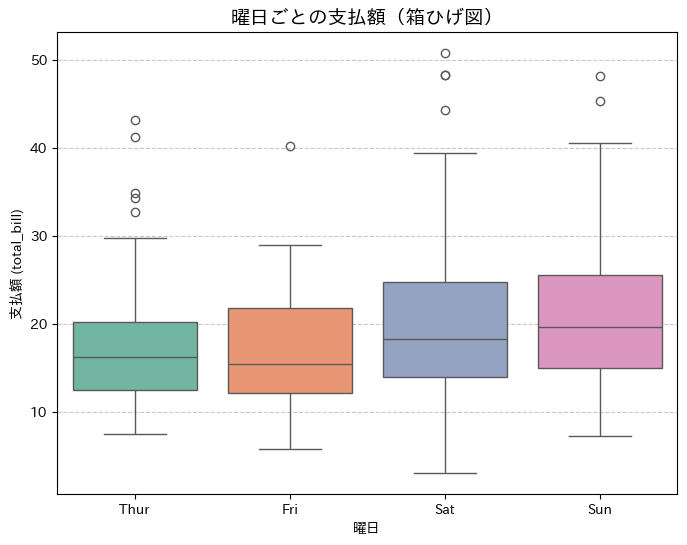

【曜日ごとの数値データ（四分位数）】
          25%    50%      75%    max   min
day                                       
Thur  12.4425  16.20  20.1550  43.11  7.51
Fri   12.0950  15.38  21.7500  40.17  5.75
Sat   13.9050  18.24  24.7400  50.81  3.07
Sun   14.9875  19.63  25.5975  48.17  7.25


/tmp/ipykernel_3241/3237053929.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(tips.groupby("day")["total_bill"].describe()[["25%", "50%", "75%", "max", "min"]])


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import japanize_matplotlib # 日本語化

# 1. データの準備（レストランの曜日別・支払額データ）
tips = sns.load_dataset("tips")

# 2. 箱ひげ図の描画
plt.figure(figsize=(8, 6))
sns.boxplot(data=tips, x="day", y="total_bill", palette="Set2")
plt.title("曜日ごとの支払額（箱ひげ図）", fontsize=14)
plt.ylabel("支払額 (total_bill)")
plt.xlabel("曜日")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 3. 数値との突合（統計コーチへの回答）
print("【曜日ごとの数値データ（四分位数）】")
print(tips.groupby("day")["total_bill"].describe()[["25%", "50%", "75%", "max", "min"]])


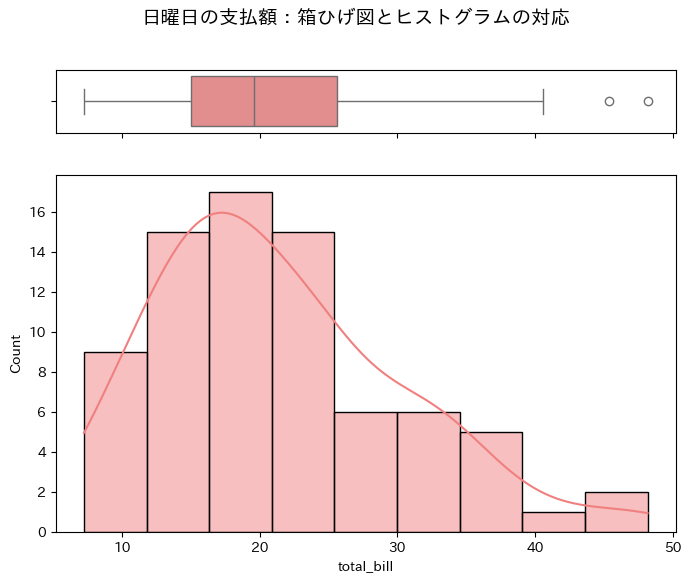

▼ 日曜日の支払額の統計量
歪度 (Skewness): 0.82  |  尖度 (Kurtosis): 0.42


In [ ]:
# 日曜日のデータに絞る
sun_tips = tips[tips['day'] == 'Sun']

# 画用紙を上下2分割して準備
fig, (ax_box, ax_hist) = plt.subplots(2, 1, sharex=True, figsize=(8, 6), gridspec_kw={"height_ratios": (.15, .85)})

# 上に箱ひげ図、下にヒストグラム（KDE曲線付き）を描画
sns.boxplot(data=sun_tips, x="total_bill", ax=ax_box, color="lightcoral")
sns.histplot(data=sun_tips, x="total_bill", kde=True, ax=ax_hist, color="lightcoral")

ax_box.set(xlabel='') # 上のグラフのX軸ラベルを消す
plt.suptitle("日曜日の支払額：箱ひげ図とヒストグラムの対応", fontsize=14)
plt.show()

# 歪度と尖度の計算
skew = sun_tips["total_bill"].skew()
kurt = sun_tips["total_bill"].kurt()
print(f"▼ 日曜日の支払額の統計量")
print(f"歪度 (Skewness): {skew:.2f}  |  尖度 (Kurtosis): {kurt:.2f}")

/tmp/ipykernel_3241/1842721471.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=tips, x="day", y="total_bill", palette="Set3", inner="quartile")


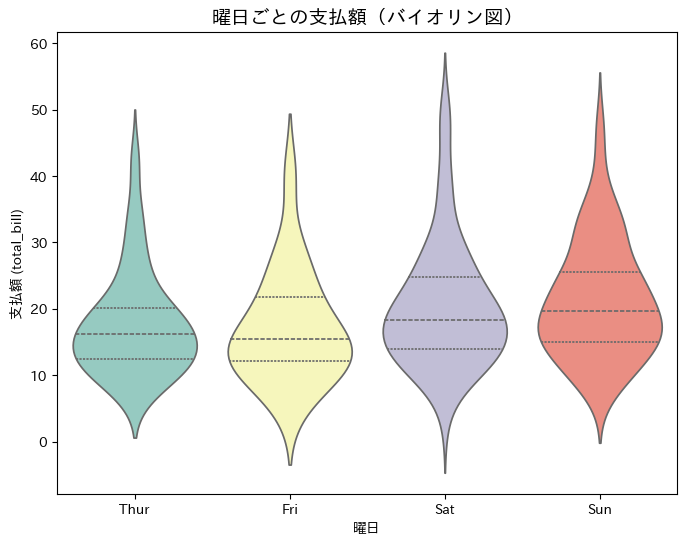

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import japanize_matplotlib # ← これが日本語化の魔法の呪文（超重要）

# バイオリン図をもう一度描画
tips = sns.load_dataset("tips")
plt.figure(figsize=(8, 6))
sns.violinplot(data=tips, x="day", y="total_bill", palette="Set3", inner="quartile")
plt.title("曜日ごとの支払額（バイオリン図）", fontsize=14)
plt.ylabel("支払額 (total_bill)")
plt.xlabel("曜日")
plt.show()

/tmp/ipykernel_3241/1475099877.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tips, x="day", y="size", palette="pastel")


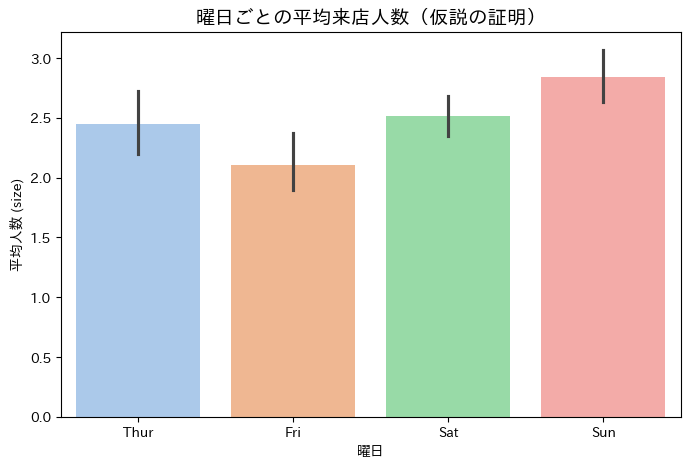

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import japanize_matplotlib

tips = sns.load_dataset("tips")

# 曜日ごとの「平均来店人数」を棒グラフにする
plt.figure(figsize=(8, 5))
sns.barplot(data=tips, x="day", y="size", palette="pastel")
plt.title("曜日ごとの平均来店人数（仮説の証明）", fontsize=14)
plt.ylabel("平均人数 (size)")
plt.xlabel("曜日")
plt.show()

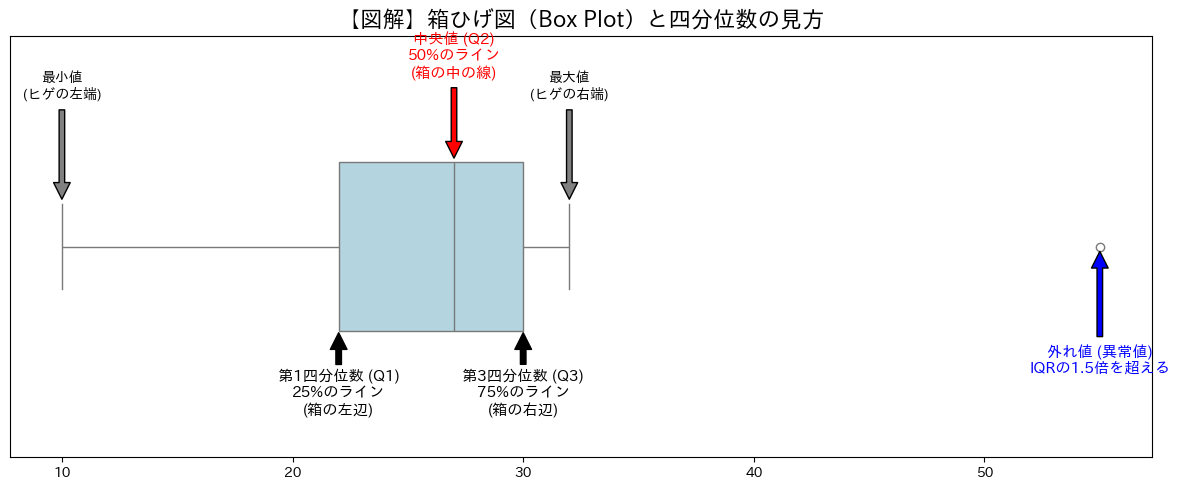

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib

# 教材用のダミーデータ（わざと外れ値を作っています）
data = [10, 20, 22, 25, 27, 28, 30, 32, 55]

# 画用紙の準備
plt.figure(figsize=(12, 5))

# 横向きの箱ひげ図を描画
sns.boxplot(x=data, color="lightblue", width=0.4)

# Obsidian用の解説テキストと矢印を配置
# 第1四分位数 (Q1)
plt.annotate('第1四分位数 (Q1)\n25%のライン\n(箱の左辺)', xy=(22, 0.2), xytext=(22, 0.4),
             arrowprops=dict(facecolor='black', shrink=0.05), ha='center', fontsize=11)
# 中央値 (Q2)
plt.annotate('中央値 (Q2)\n50%のライン\n(箱の中の線)', xy=(27, -0.2), xytext=(27, -0.4),
             arrowprops=dict(facecolor='red', shrink=0.05), ha='center', fontsize=11, color='red')
# 第3四分位数 (Q3)
plt.annotate('第3四分位数 (Q3)\n75%のライン\n(箱の右辺)', xy=(30, 0.2), xytext=(30, 0.4),
             arrowprops=dict(facecolor='black', shrink=0.05), ha='center', fontsize=11)
# 最小値・最大値・外れ値
plt.annotate('最小値\n(ヒゲの左端)', xy=(10, -0.1), xytext=(10, -0.35),
             arrowprops=dict(facecolor='gray', shrink=0.05), ha='center', fontsize=10)
plt.annotate('最大値\n(ヒゲの右端)', xy=(32, -0.1), xytext=(32, -0.35),
             arrowprops=dict(facecolor='gray', shrink=0.05), ha='center', fontsize=10)
plt.annotate('外れ値 (異常値)\nIQRの1.5倍を超える', xy=(55, 0), xytext=(55, 0.3),
             arrowprops=dict(facecolor='blue', shrink=0.05), ha='center', fontsize=11, color='blue')

# タイトルなどの見た目調整
plt.title("【図解】箱ひげ図（Box Plot）と四分位数の見方", fontsize=16, fontweight='bold')
plt.yticks([]) # Y軸の無駄な目盛りを消す
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 6))


<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

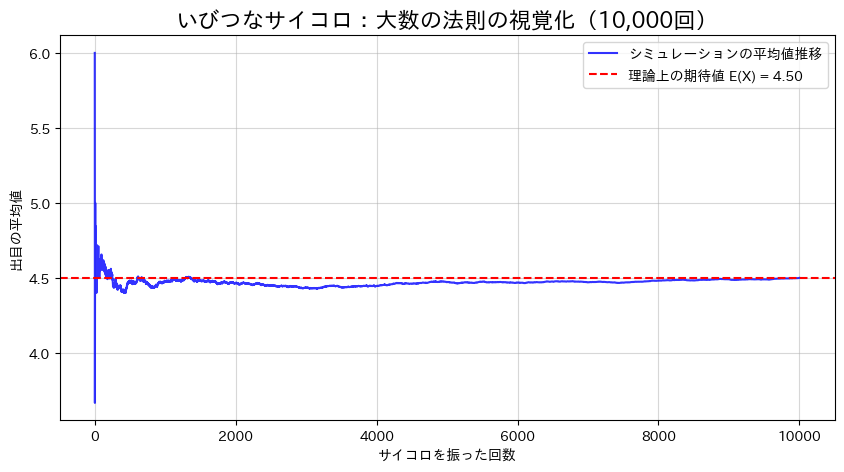

▼ 理論上の計算結果（数式の世界）
期待値: 4.5000  |  分散: 3.2500
▼ 1万回シミュレーション結果（現実の世界）
平均値: 4.5000  |  分散: 3.2634


In [ ]:
!pip install japanize_matplotlib
import numpy as np
import matplotlib.pyplot as plt
import japanize_matplotlib

# 1. いびつなサイコロの設定（6が50%の確率で出る）
faces = np.array([1, 2, 3, 4, 5, 6])
probs = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.5])

# 理論上の期待値と分散を計算
E_X = np.sum(faces * probs)
V_X = np.sum((faces - E_X)**2 * probs)

# 2. シミュレーション（1万回振る！）
n_trials = 10000
rolls = np.random.choice(faces, p=probs, size=n_trials)

# 振るたびに「そこまでの平均値」がどう変わるか計算（累積平均）
cumulative_averages = np.cumsum(rolls) / np.arange(1, n_trials + 1)

# 3. グラフで「大数の法則」を可視化
plt.figure(figsize=(10, 5))
plt.plot(cumulative_averages, label="シミュレーションの平均値推移", color="blue", alpha=0.8)
plt.axhline(y=E_X, color="red", linestyle="--", label=f"理論上の期待値 E(X) = {E_X:.2f}")
plt.title("いびつなサイコロ：大数の法則の視覚化（10,000回）", fontsize=16)
plt.xlabel("サイコロを振った回数")
plt.ylabel("出目の平均値")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

print(f"▼ 理論上の計算結果（数式の世界）")
print(f"期待値: {E_X:.4f}  |  分散: {V_X:.4f}")
print(f"▼ 1万回シミュレーション結果（現実の世界）")
print(f"平均値: {np.mean(rolls):.4f}  |  分散: {np.var(rolls):.4f}")

▼ 性別ごとの生存率（条件付き確率の表）
survived         0         1
sex                         
female    0.257962  0.742038
male      0.811092  0.188908
All       0.616162  0.383838
--------------------------------------------------


/tmp/ipykernel_3241/2456841773.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=titanic, x="sex", y="survived", palette="Set2")


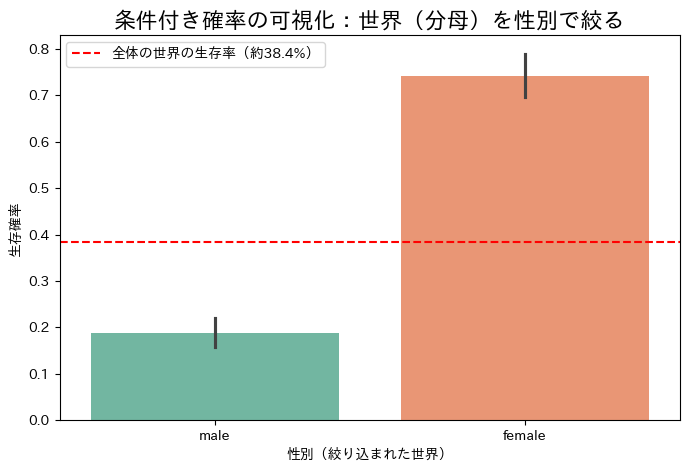

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# 1. タイタニックデータの読み込み
titanic = sns.load_dataset("titanic")

# 2. クロス集計表（数値で見る条件付き確率）
# normalize='index' で、行（性別）ごとの確率（100%）に変換する
cross_tab = pd.crosstab(titanic['sex'], titanic['survived'], margins=True, normalize='index')
print("▼ 性別ごとの生存率（条件付き確率の表）")
print(cross_tab)
print("-" * 50)

# 3. グラフで直感的に可視化
plt.figure(figsize=(8, 5))
sns.barplot(data=titanic, x="sex", y="survived", palette="Set2")
# 全体の生存率を赤い点線で引く
total_survival_rate = titanic['survived'].mean()
plt.axhline(y=total_survival_rate, color="red", linestyle="--", label=f"全体の世界の生存率（約{total_survival_rate*100:.1f}%）")

plt.title("条件付き確率の可視化：世界（分母）を性別で絞る", fontsize=16)
plt.ylabel("生存確率")
plt.xlabel("性別（絞り込まれた世界）")
plt.legend()
plt.show()

In [ ]:
s1="こんにちは"
s2="バイバイ"
print(s1 + s2) # 連結
print(s1 * 3) # 3回連結
s1 = s1 + s2
print(s1, s1 + s2)

こんにちはバイバイ
こんにちはこんにちはこんにちは
こんにちはバイバイ こんにちはバイバイバイバイ


In [ ]:
n = 10
total = n * (n + 1) // 2
print(total)

55


In [ ]:
a = 1
b = 4
c = 1
D = b**2 - 4*a*c
if D >0:
  A = (-b + D**0.5)/2*a
  B = (-b - D**0.5)/2*a
  print(a,"x**2 +",b,"x +",a,"= 0の解は",A,"と",B)
elif D == 0:
  A = -b/2*a
  print(a,"x**2 +",b,"x +",a,"= 0の解は",A)
else:
  print(a,"x**2 +",b,"x +",a,"= 0の解は虚数")

1 x**2 + 4 x + 1 = 0の解は -0.2679491924311228 と -3.732050807568877


In [ ]:
n = 2000
if (n % 4 == 0 and n % 100 != 0) or n % 400 == 0:
  print(n,"年はうるう年")
else:
  print(n,"年はうるう年ではない")

2000 年はうるう年


In [ ]:
n = 1
total = 0
while n <= 10:
  total = total + n
  n = n + 1
print (total)

55


In [ ]:
n = 1
total = 0
while n <= 10:
  n = n + 1
  total = total + n
print (total)

65


In [ ]:
n = 1
sum = 0
while n <= 13:
  sum = sum + n**2
  n = n + 2
print(sum)

455


In [ ]:
n = 1
m = 2
sum = 0
while n <= 11:
  sum = sum + n**3
  n = n + 2
while m <= 10:
  sum = sum - m
  m = m + 2
print(sum)

2526


In [ ]:
n = 1
while n <= 50:
  if n % 3 != 0 and n % 5 == 0:
    print(n)
  n = n + 1

5
10
20
25
35
40
50


In [ ]:
n = 1
while n <= 50:
  if n % 3 != 0 and n % 5 != 0 and n % 7 != 0:
    print(n)
  n = n + 1



1
2
4
8
11
13
16
17
19
22
23
26
29
31
32
34
37
38
41
43
44
46
47


In [ ]:
n = 1
sum = 0
while sum <= 1000:
  sum = sum + n
  n = n + 1
print(n,"までで合計は",sum)

46 までで合計は 1035


In [ ]:
n = 1
sum = 0
while True:
  if n % 2 != 0 :
    sum = sum + n**3
  if n % 2 == 0 :
    sum = sum + n
  if sum > 500:
    break
  n = n + 1
print(n,"の時",sum)

7 の時 508


In [ ]:
n=1
sum=0
while True :
  sum=sum+n
  if sum>1000:
    break
  n=n+1
print(n,"の時",sum)

45 の時 1035


In [ ]:
n=289
m=2
if n ==1:
  print(n,"は素数ではない")
elif n==2:
  print(n,"は素数")
elif n<=0 or n%1!=0:
  print("正の整数を入力してください")
else:
  while True:
    if n%m==0:
      print(n,"は",m,"で割れるため素数ではない")
      break
    m=m+1
    if m>n**0.5:
      print(n,"は素数")
      break

289 は 17 で割れるため素数ではない


In [ ]:
import math
for n in range(2,101):
  i=2
  while True:
    if i>math.sqrt(n):
      break
    if n%i==0:
      break
    i=i+1
  if i>math.sqrt(n):
    print(n,"は素数")

2 は素数
3 は素数
5 は素数
7 は素数
11 は素数
13 は素数
17 は素数
19 は素数
23 は素数
29 は素数
31 は素数
37 は素数
41 は素数
43 は素数
47 は素数
53 は素数
59 は素数
61 は素数
67 は素数
71 は素数
73 は素数
79 は素数
83 は素数
89 は素数
97 は素数


In [ ]:
import math
n=3
i=2
while True:
    if i>math.sqrt(n):
      break
    if n%i==0:
      break
    i=i+1
if i>math.sqrt(n):
    print(n,"は素数")

3 は素数


In [ ]:
import random
ans=random.randint(1,100)
m=0
print("1から100までの数字を当ててください")
while True:
  inp = int(input("数値は？"))
  if inp == ans:
    print("正解です",m+1,"回で当てました")
    break
  elif inp < ans:
    print("もっと大きいです")
  else:
    print("もっと小さいです")
  m=m+1


1から100までの数字を当ててください


KeyboardInterrupt: Interrupted by user

In [ ]:
num=float(input("正の実数を入力してください"))
eps=0.0000000001
n=num
m=0
while n-m>=eps:
  guess=(n+m)/2
  if guess**2==num:
    print(guess)
  elif guess**2>num:
    n=guess
  else:
    m=guess
print(guess)

正の実数を入力してください9
3.000000000021828


In [ ]:
for n in range(1,51):
  if n%3==0 or n%5==0:
    print(n)


3
5
6
9
10
12
15
18
20
21
24
25
27
30
33
35
36
39
40
42
45
48
50


In [ ]:
for n in range(2,51,2):
  if n%3==0 and n%5!=0:
    print(n)

6
12
18
24
36
42
48


In [ ]:
for n in range(50,1,-2):
  if n%3==0 and n%5!=0:
    print(n)

48
42
36
24
18
12
6


In [ ]:
import math
n=int(input("正の整数を入力してください"))

if n < 2:
  print(n,"は素数ではない")
else:
  for i in range(2, int(math.sqrt(n)) + 2):
    if n % i == 0:
      break

  if i>math.sqrt(n):
    print(n, "は素数")
  else:
    print(n, "は",i,"で割れるため素数ではない")

正の整数を入力してください2
2 は素数


In [ ]:
import math
for n in range(2,101):
  if n < 2:
    print(n,"は素数ではない")
  else:
    for i in range(2, int(math.sqrt(n)) + 2):
      if n % i == 0:
        break

    if i>math.sqrt(n):
      print(n, "は素数")
    else:
      print(n, "は",i,"で割れるため素数ではない")

2 は素数
3 は素数
4 は 2 で割れるため素数ではない
5 は素数
6 は 2 で割れるため素数ではない
7 は素数
8 は 2 で割れるため素数ではない
9 は 3 で割れるため素数ではない
10 は 2 で割れるため素数ではない
11 は素数
12 は 2 で割れるため素数ではない
13 は素数
14 は 2 で割れるため素数ではない
15 は 3 で割れるため素数ではない
16 は 2 で割れるため素数ではない
17 は素数
18 は 2 で割れるため素数ではない
19 は素数
20 は 2 で割れるため素数ではない
21 は 3 で割れるため素数ではない
22 は 2 で割れるため素数ではない
23 は素数
24 は 2 で割れるため素数ではない
25 は 5 で割れるため素数ではない
26 は 2 で割れるため素数ではない
27 は 3 で割れるため素数ではない
28 は 2 で割れるため素数ではない
29 は素数
30 は 2 で割れるため素数ではない
31 は素数
32 は 2 で割れるため素数ではない
33 は 3 で割れるため素数ではない
34 は 2 で割れるため素数ではない
35 は 5 で割れるため素数ではない
36 は 2 で割れるため素数ではない
37 は素数
38 は 2 で割れるため素数ではない
39 は 3 で割れるため素数ではない
40 は 2 で割れるため素数ではない
41 は素数
42 は 2 で割れるため素数ではない
43 は素数
44 は 2 で割れるため素数ではない
45 は 3 で割れるため素数ではない
46 は 2 で割れるため素数ではない
47 は素数
48 は 2 で割れるため素数ではない
49 は 7 で割れるため素数ではない
50 は 2 で割れるため素数ではない
51 は 3 で割れるため素数ではない
52 は 2 で割れるため素数ではない
53 は素数
54 は 2 で割れるため素数ではない
55 は 5 で割れるため素数ではない
56 は 2 で割れるため素数ではない
57 は 3 で割れるため素数ではない
58 は 2 で割れるため素数ではない
59 は素数
60 は 2 で割れるため素数ではない
61 は素数
62 は 2 で割れるため素数ではない
63 は 3 で割れるため素数ではない
64

In [ ]:
for i in range (1,10):
  for j in range(1,10):
    print("%4d"%(i*j),end="")
  print()

   1   2   3   4   5   6   7   8   9
   2   4   6   8  10  12  14  16  18
   3   6   9  12  15  18  21  24  27
   4   8  12  16  20  24  28  32  36
   5  10  15  20  25  30  35  40  45
   6  12  18  24  30  36  42  48  54
   7  14  21  28  35  42  49  56  63
   8  16  24  32  40  48  56  64  72
   9  18  27  36  45  54  63  72  81


In [ ]:
for i in range(1,10):
  for j in range(1,10):
    print(f"{i*j:4d}",end="")
  print()

   1   2   3   4   5   6   7   8   9
   2   4   6   8  10  12  14  16  18
   3   6   9  12  15  18  21  24  27
   4   8  12  16  20  24  28  32  36
   5  10  15  20  25  30  35  40  45
   6  12  18  24  30  36  42  48  54
   7  14  21  28  35  42  49  56  63
   8  16  24  32  40  48  56  64  72
   9  18  27  36  45  54  63  72  81


In [ ]:
n=float(input("整数を入力してください"))
def foo(n):
  if n%2==0:
    return n//2
  else:
    return 3*n+1
print(foo(n))

KeyboardInterrupt: Interrupted by user

In [ ]:
n=float(input("正の整数を入力してください"))
i=n-1
def numdiv(i):
  while i>=1:
    if n%i==0:
      break
    i=i-1
  return i
print(numdiv(i))

正の整数を入力してください11359
307.0


In [ ]:
def numpow(n,m):
  count=0
  while True:
    if n%m==0:
      n=n//m
      count=count+1
    else:
      break
  return count
print("nをmでなんか割れるかを算出するプログラムです")
n=float(input("nに入る正の整数を入力してください"))
m=float(input("mに入る正の整数を入力してください"))
print(numpow(n,m))


nをmでなんか割れるかを算出するプログラムです
nに入る正の整数を入力してください1
mに入る正の整数を入力してください3
0


In [ ]:
def power(n,m):
  return n**m
n=float(input("正の整数を入力してください"))
m=float(input("正の整数を入力してください"))
print(power(n,m)+power(m,n))

正の整数を入力してください2
正の整数を入力してください3
17.0


In [ ]:
def sqrtint(a,b):
  return (a+b)**0.5//1
sum=sqrtint(2,4)+sqrtint(6,8)+sqrtint(10,12)
print(sum)

9.0


In [ ]:
def isPrime(n):
  if n < 2:
    return False
  for i in range(2, int(n**0.5) + 1):
    if n % i == 0:
      return False
  return True

for n in range(100, 0, -1):
  if isPrime(n):
    print(n)

97
89
83
79
73
71
67
61
59
53
47
43
41
37
31
29
23
19
17
13
11
7
5
3
2


In [ ]:
import random
price=random.randint(1,1000)
print("お値段",price,"円になります")
n=float(input("いくら出しますか？(1000円以内)"))
if price>n:
  print("足りねえよ")
else:
  print(int(n),"円、お預かりいたします")
  m=n-price
  i=k=o=l=p=0
  if m>=500:
    m=m-500
    i=1
  while m>=100:
    m=m-100
    k=k+1
  if m>=50:
    m=m-50
    o=1
  while m>=10:
    m=m-10
    l=l+1
  if m>=5:
    p=1
  if i==k==l==i==o==p==m==0:
    print("ちょうどいただきます。ありがとうございました")
  else:
    print("500円玉",i,"枚と100円玉",k,"枚と50円玉",o,"枚と10円玉",l,"枚と5円玉",p,"枚と1円玉",int(m),"枚のお返しです。ありがとうございました")



お値段 762 円になります
いくら出しますか？(1000円以内)762
762 円、お預かりいたします
ちょうどいただきます。ありがとうございました


In [ ]:
from typing import ChainMap
import random
price=random.randint(1,1000)
print(f"お値段{price}円になります")
n=int(input("いくら出しますか(1000円以内)？"))
if price>n:
  print("足りねえよ")
elif price==n:
  print(f"{n}円ちょうどいただきます")
else:
  print(f"{n}円お預かりします")
  change=n-price
  coins=[500,100,50,10,1]
  change_details=[]
  for coin in coins:
    count=change//coin
    if count>0:
      change_details.append(f"{coin}円玉{count}枚")
      change=change%coin
  change_text="と".join(change_details)
  print(f"{change_text}のお返しです")

お値段66円になります
いくら出しますか(1000円以内)？1000
1000円お預かりします
500円玉1枚と100円玉4枚と10円玉3枚と1円玉4枚のお返しです


In [ ]:
for n in range(100,999):
  m=n+1
  sum_n=n//100+(n%100)//10+n%10
  sum_m=m//100+(m%100)//10+m%10
  if sum_n==2*sum_m:
    print(n,m)

169 170
259 260
349 350
439 440
529 530
619 620
709 710


In [ ]:
def prstar(n):
  for i in range(n):
   print("*",end="")
prstar(5)

*****

In [ ]:
def mydiv(m,n):
  return m//n,m%n
m=int(input("mを入力してください"))
n=int(input("nを入力してください"))
r=mydiv(m,n)
print(r)

mを入力してください100
nを入力してください3
(33, 1)


In [ ]:
numlist=[]
for n in range(1,51):
  if n%3==0 and n%5==0:
    numlist.append(n)
print(numlist)

[15, 30, 45]


In [ ]:
nl = [ j * j for j in range(4) if j % 2 == 0]
print(nl)

[0, 4]


In [ ]:
def maxlist(n):
  m=sorted(n)
  return m[len(m)-1]
L1 = [3, 8, 2, 4, 1, 7]
n=L1
print(maxlist(n))


10


In [ ]:
def avelist(n):
  m=sum(n)/len(n)
  return m
L1 = [3, 8, 2, 4, 1, 7]
print(avelist(L1))

4.166666666666667


In [ ]:
def extoddlist(n):
  m=[]
  for i in n :
    if i%2==1:
      m.append(i)
  return m
L1 = [3, 8, 2, 4, 1, 7]
print(extoddlist(L1))

[3, 1, 7]


In [ ]:
def grthanNlist(n):
  m=[]
  for i in n:
    if i>N:
      m.append(i)
  return m
N=int(input("Nを入力してください"))
L1 = [3, 8, 2, 4, 1, 7]
print(grthanNlist(L1))

Nを入力してください5
[8, 7]


In [ ]:
def allgrtthanN(n):
  for i in n:
    if i<=N:
      return False
  return True


N=int(input("Nを入力してください"))
L1 = [3, 8, 2, 4, 1, 7]
if allgrtthanN(L1):
  print("OK")
else:
  print("ダメ ")


Nを入力してください1
ダメ 


In [ ]:
def anygrtthanN(n):
  for i in n:
    if i>N:
      return True
  return False


N=int(input("Nを入力してください"))
L1 = [3, 8, 2, 4, 1, 7]
if anygrtthanN(L1):
  print("OK")
else:
  print("ダメ ")

Nを入力してください9
ダメ 


In [ ]:
import random
list=[]
i=0
while i<=19:
  n=random.randint(1,100)
  list.append(n)
  i=i+1
print(list)

[1, 30, 72, 88, 66, 9, 97, 96, 52, 75, 8, 17, 7, 23, 73, 35, 75, 29, 20, 91]


In [ ]:
import random
list=[]
while len(list)<=19:
  n=random.randint(1,100)
  if n not in list:
    list.append(n)
print(list)

[2, 63, 19, 11, 30, 96, 95, 55, 7, 62, 74, 6, 39, 41, 75, 29, 100, 86, 54, 64]


In [ ]:
import random
def mkrandlist(n):
  list=[]
  while len(list)<n:
    i=random.randint(1,100)
    if i not in list:
      list.append(i)
  return sorted(list)
print(mkrandlist(20))

[9, 13, 15, 17, 22, 30, 31, 35, 41, 45, 46, 48, 52, 56, 67, 71, 90, 94, 96, 97]


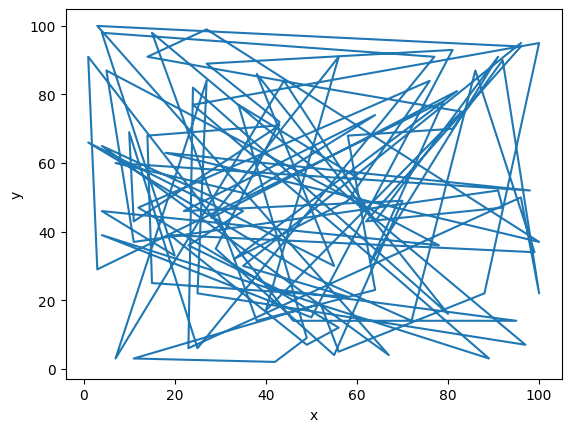

In [ ]:
import random
x=[]
y=[]
for i in range(99):
  x.append(random.randint(1,100))
  y.append(random.randint(1,100))
import matplotlib.pyplot as plt
plt.plot(x,y)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

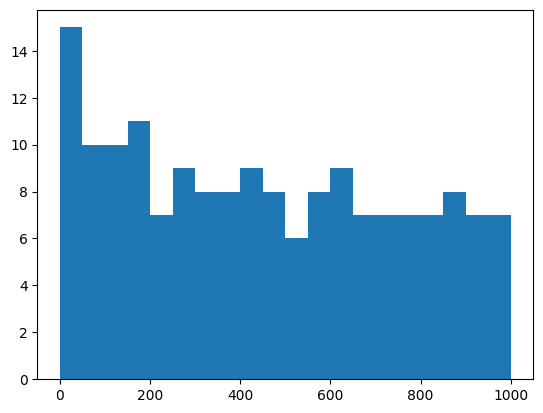

In [ ]:
list=[2,3]
for n in range(2,1001):
  for i in range(2,int(n**0.5)+1):
    if n%i==0:
      x=False
      break
    x=True
  if x==True:
    list.append(n)
import matplotlib.pyplot as plt
plt.hist (list, bins=range(0,1001,50))
plt.show()

In [5]:
def f(x):
  return x**2-2
def df(x):
  return 2*x
def nextX(x):
  return x-f(x)/df(x)
x=2
while abs(nextX(x)-x)>=0.0001:
  x=nextX(x)
print(x)

1.4142156862745099


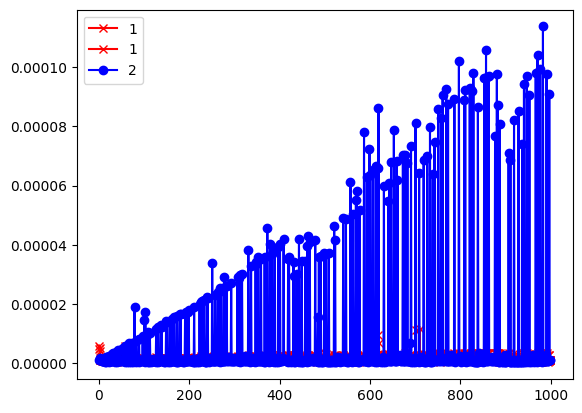

/tmp/ipykernel_2858/3199145432.py:76: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


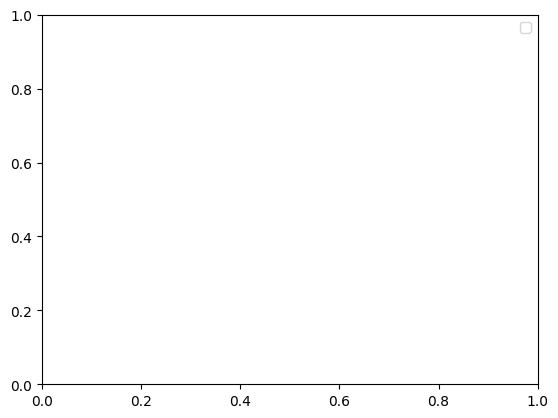

In [27]:
import time
import matplotlib.pyplot as plt

def isPrime_1(n):
    # nの平方根を整数（int）に変換し、探索範囲に含めるために+1する
    for i in range(2, int(n**0.5) + 1):
        if n % i == 0:
            return False
    return True

def isPrime_2(n):
    for i in range(2, n):
        if n % i == 0:
            return False
    return True

x = []
y_1 = []
y_2 = []

for n in range(1, 1000):
    start_1 = time.time()
    isPrime_1(n)
    end_1 = time.time()
    # = を外し、括弧のなかに値を入れる
    y_1.append(end_1 - start_1)

    start_2 = time.time()
    isPrime_2(n)
    end_2 = time.time()
    # = を外し、括弧のなかに値を入れる
    y_2.append(end_2 - start_2)

    x.append(n)

plt.plot(x, y_1, marker="x", color="red", label="1")
import time
import matplotlib.pyplot as plt

def isPrime_1(n):
    # nの平方根を整数（int）に変換し、探索範囲に含めるために+1する
    for i in range(2, int(n**0.5) + 1):
        if n % i == 0:
            return False
    return True

def isPrime_2(n):
    for i in range(2, n):
        if n % i == 0:
            return False
    return True

x = []
y_1 = []
y_2 = []

for n in range(1, 1000):
    start_1 = time.time()
    isPrime_1(n)
    end_1 = time.time()
    # = を外し、括弧のなかに値を入れる
    y_1.append(end_1 - start_1)

    start_2 = time.time()
    isPrime_2(n)
    end_2 = time.time()
    # = を外し、括弧のなかに値を入れる
    y_2.append(end_2 - start_2)

    x.append(n)

plt.plot(x, y_1, marker="x", color="red", label="1")
plt.plot(x, y_2, marker="o", color="blue", label="2")
plt.legend()
plt.show()
plt.legend()
plt.show()




In [35]:
def ugrit(a,b):
  if a%b==0:
    return b
  else:
    a,b=b,a%b
    return ugrit(a,b)
a=int(input("正の整数aを入力してください"))
b=int(input("正の整数bを入力してください"))
if a<b:
  a,b=b,a
print(ugrit(a,b))

正の整数aを入力してください10
正の整数bを入力してください3
1


In [37]:
def ugrit(a,b):
  while a%b!=0:
    a,b=b,a%b
  return b
a=int(input("正の整数aを入力してください"))
b=int(input("正の整数bを入力してください"))
if a<b:
  a,b=b,a
print(ugrit(a,b))

正の整数aを入力してください１０
正の整数bを入力してください１
1


In [41]:
def fib(n):
  if n==0 or n==1:
    return 1
  else:
    return fib(n-1)+fib(n-2)
n=int(input("正の整数nを入力してください"))
print(fib(n))

正の整数nを入力してください5
8


In [12]:
def fib(n):
  X1=1
  X0=1
  for i in range(n-1):
    X2=X1+X0
    X1,X0=X2,X1
  if n==0 or n==1:
    return 1
  return X2
n=int(input("正の整数nを入力してください"))
print(fib(n))

正の整数nを入力してください2
2


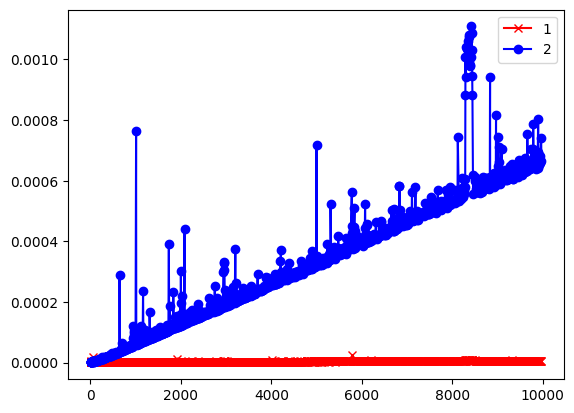

In [29]:
def isPrime1(n):
  for i in range(2,int(n**0.5)+1):
    if n%i==0:
      return False
  return True
def isPrime2(n):
  for i in range(2,n):
    if n%i==0:
      return False
  return True
import time
import matplotlib.pyplot as plt
x=[]
y_1=[]
y_2=[]
for n in range(1,10000):
  s1=time.time()
  isPrime1(n)
  e1=time.time()
  if isPrime1(n)==True:
    x.append(n)
    y_1.append(e1-s1)
  s2=time.time()
  isPrime2(n)
  e2=time.time()
  if isPrime2(n)==True:
    y_2.append(e2-s2)
plt.plot(x,y_1,marker="x",color="red",label="1")
plt.plot(x,y_2,marker="o",color="blue",label="2")
plt.legend()
plt.show()

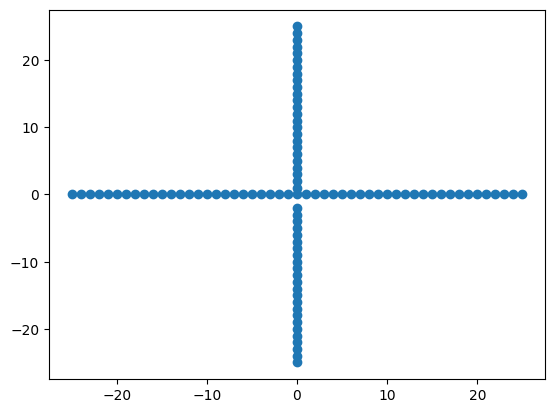

In [38]:
def isPrime(n):
  for i in range(2,int(n**0.5)+1):
    if n%i==0:
      return False
  return True
x=[0]
y=[0]
for n in range(1,100):
  if n%4==1:
    x.append(n//4+1)
    y.append(0)
  if n%4==2:
    x.append(0)
    y.append(n//4+1)
  if n%4==3:
    x.append(-1*(n//4+1))
    y.append(0)
  if n%4==0:
    x.append(0)
    y.append(-1*(n//4+1))
if isPrime(n)==True:
    del x[n-1]
    del y[n-1]
import matplotlib.pyplot as plt
plt.scatter(x,y,marker="o")
plt.show()

In [ ]:
import math
def spiral(n):
  if n==0:
    return (0,0)
  root = math.ceil(math.sqrt(n))
  if root%2 == 0:
    root = root+1
  k = (root-1)//2
  M = (2*k+1)**2
